In [ ]:
import pickle
import numpy as np
from tensorflow import keras
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, \
    f1_score, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
model = keras.models.load_model('/content/drive/MyDrive/AUT/Project/Models/Conv1D-MFCCs_Conv2D-MEL_EN-LSTM_DE-GRU')

In [ ]:
PICKLE_PATH = "/content/drive/MyDrive/AUT/Project/Features/DATA_MFCC30_MEL128.pkl"

In [ ]:
def load_data():
    with open(PICKLE_PATH, "rb") as input:
        DATA = pickle.load(input)

    X1 = np.array(DATA["mfccs"], dtype=np.float32)
    X2 = np.array(DATA["mel_spec"], dtype=np.float32)
    y1 = np.array(DATA["labels"]["instrument"], dtype=np.int8)
    y2 = np.array(DATA["labels"]["scale"], dtype=np.int8)

    return X1, X2, y1, y2

In [ ]:
def prepare_dataset():
    X1, X2, y1, y2 = load_data()

    X1_train, X1_test, X2_train, X2_test, y1_train, y1_test, y2_train, y2_test = \
        train_test_split(X1, X2, y1, y2, test_size=0.15, shuffle=True, random_state=0)

    X1_test, X1_val, X2_test, X2_val, y1_test, y1_val, y2_test, y2_val = \
        train_test_split(X1_test, X2_test, y1_test, y2_test, test_size=0.5, shuffle=True, random_state=0)

    # X2: 4d array -> (num_samples, 216, 128, 1)
    X_train = (X1_train, X2_train[..., np.newaxis])
    X_test = (X1_test, X2_test[..., np.newaxis])
    X_val = (X1_val, X2_val[..., np.newaxis])

    Y_train = (y1_train, y2_train)
    Y_test = (y1_test, y2_test)
    Y_val = (y1_val, y2_val)

    return X_train, X_test, X_val, Y_train, Y_test, Y_val

In [ ]:
X_train, X_test, X_val, Y_train, Y_test, Y_val = prepare_dataset()
(y1_test, y2_test) = Y_test

In [ ]:
prediction1, prediction2 = model.predict(X_test)
pd1 = np.argmax(prediction1, axis=-1)
pd2 = np.argmax(prediction2, axis=-1)

22/22 [==============================] - 20s 653ms/step


In [ ]:
Scale = ["SHOUR", "SEGAH", "MAHOUR", "HOMAYOUN", "RASTPANJGAH", "NAVA", "CHAHARGAH"]
# Scale =["شور", "سه‌گاه", "ماهور", "همایون", "راست پنج‌گاه", "نوا", "چهارگاه"]
print('\nClassification Report\n')
print(classification_report(pd2, y2_test, target_names=Scale))
# cm = confusion_matrix(y, prediction)


Classification Report

              precision    recall  f1-score   support

       SHOUR       0.99      0.99      0.99       105
       SEGAH       0.97      0.99      0.98       114
      MAHOUR       0.98      0.98      0.98       105
    HOMAYOUN       1.00      0.96      0.98        90
 RASTPANJGAH       0.96      1.00      0.98        80
        NAVA       0.99      0.99      0.99        79
   CHAHARGAH       1.00      0.98      0.99       102

    accuracy                           0.98       675
   macro avg       0.98      0.98      0.98       675
weighted avg       0.98      0.98      0.98       675



In [ ]:
Instrument = ["TAR", "KAMANCHEH", "SANTOOR", "SETAR", "NEY"]
# Instrument = ["تار", "کمانچه", "سنتور", "ستار", "نی"]
print('\nClassification Report\n')
print(classification_report(pd1, y1_test, target_names=Instrument))


Classification Report

              precision    recall  f1-score   support

         TAR       0.96      1.00      0.98       110
   KAMANCHEH       1.00      1.00      1.00       117
     SANTOOR       1.00      1.00      1.00       196
       SETAR       1.00      1.00      1.00       148
         NEY       1.00      0.96      0.98       104

    accuracy                           0.99       675
   macro avg       0.99      0.99      0.99       675
weighted avg       0.99      0.99      0.99       675



In [ ]:
cm1 = confusion_matrix(y1_test, pd1)
cm2 = confusion_matrix(y2_test, pd2)

In [ ]:
#English version


# def plotting_cm(cm, label):
#     fig = plt.figure(figsize=(10,10))
#     plt.clf()
#     plt.title('Confusion Matrix')

#     cmap = sns.cubehelix_palette(light=1, as_cmap=True)

#     group_counts = ["{0:0.0f}".format(value) for value in cm.flatten()]
#     # group_percentages = ["{0:.2%}".format(value) for value in cm.flatten()/np.sum(cm)]
#     num_labels = len(label)
#     labels = [f"{v1}" for v1 in group_counts]
#     labels = np.asarray(labels).reshape(num_labels,num_labels)

#     x_axis_labels = label # labels for x-axis
#     y_axis_labels = label # labels for y-axis

#     # create seaborn heatmap with required labels
#     sns.heatmap(cm, xticklabels=x_axis_labels, yticklabels=y_axis_labels, annot=labels, fmt='', cmap=cmap)
#     plt.savefig('confusion_matrix.png', dpi=100, bbox_inches='tight')
#     plt.show()

In [ ]:
!pip install --upgrade arabic-reshaper python-bidi pillow
!pip install PIL

In [13]:
import arabic_reshaper
text_to_be_reshaped = 'اللغة العربية رائعة'
reshaped_text = arabic_reshaper.reshape(text_to_be_reshaped)

from bidi.algorithm import get_display
bidi_text = get_display(reshaped_text)

from PIL import ImageFont, ImageDraw, Image

# We load Arial since it's a well known font that supports Arabic Unicode
font = ImageFont.truetype('Arial', 40)

image = Image.new('RGBA', (800, 600), (255,255,255,0))
image_draw = ImageDraw.Draw(image)
image_draw.text((10,10), bidi_text, fill=(255,255,255,128), font=font)

# Now the text is rendered properly on the image, you can save it to a file or just call `show` to see it working
image.show()

ImportError: ignored

In [3]:
!pip install --upgrade arabic-reshaper
import arabic_reshaper

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
# Persian Version

def plotting_cm(cm, label):
    fig = plt.figure(figsize=(10,10))
    plt.clf()
    plt.title('Confusion Matrix')

    cmap = sns.cubehelix_palette(light=1, as_cmap=True)

    group_counts = ["{0:0.0f}".format(value) for value in cm.flatten()]
    # group_percentages = ["{0:.2%}".format(value) for value in cm.flatten()/np.sum(cm)]
    num_labels = len(label)
    labels = [f"{v1}" for v1 in group_counts]
    labels = np.asarray(labels).reshape(num_labels,num_labels)

    label = [arabic_reshaper.reshape(lab)[::-1] for lab in  label]
    x_axis_labels = label # labels for x-axis
    y_axis_labels = label # labels for y-axis

    # create seaborn heatmap with required labels
    sns.heatmap(cm, xticklabels=x_axis_labels, yticklabels=y_axis_labels, annot=labels, fmt='', cmap=cmap)
    plt.savefig('confusion_matrix.png', dpi=100, bbox_inches='tight')
    plt.show()

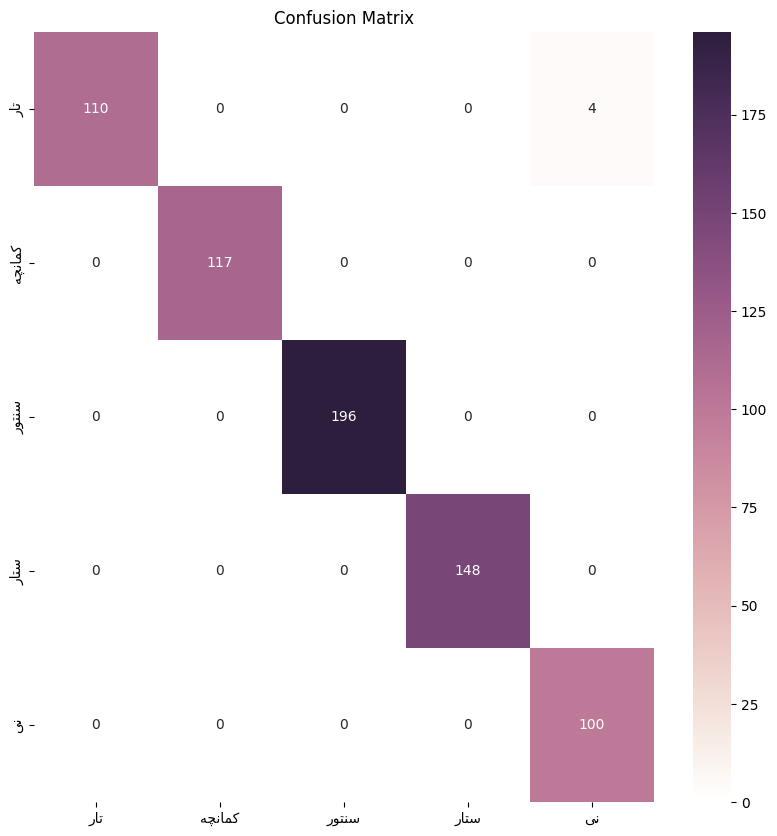

In [ ]:
plotting_cm(cm1, Instrument)

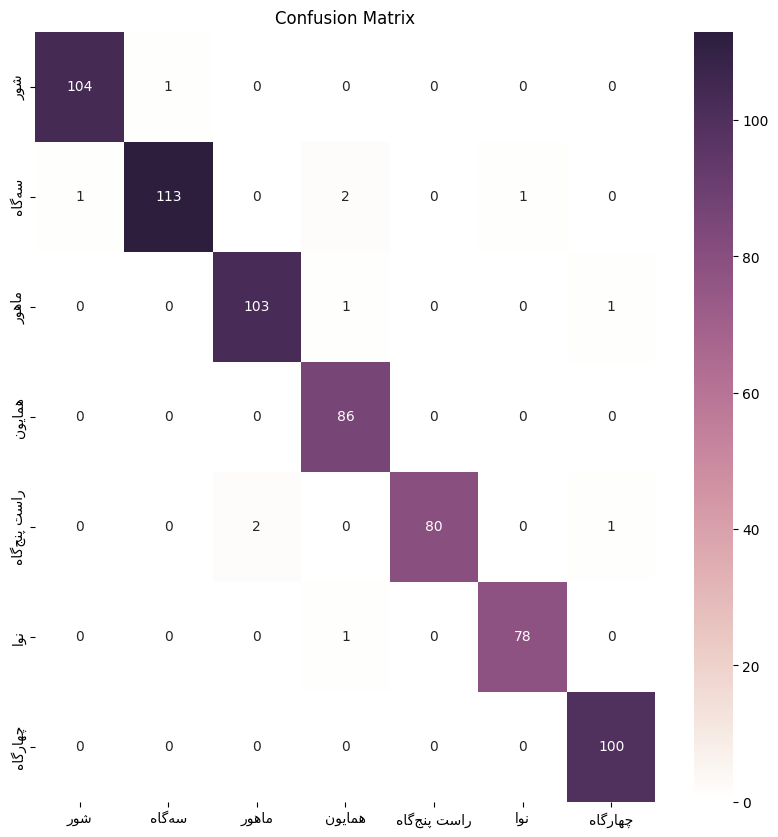

In [ ]:
plotting_cm(cm2, Scale)

In [ ]:
def accuracy_performance(y_test, y_pred):

    print('\nAccuracy: {:.2f}\n'.format(accuracy_score(y_test, y_pred)))

    print('Micro Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='micro')))
    print('Micro Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='micro')))
    print('Micro F1-score: {:.2f}\n'.format(f1_score(y_test, y_pred, average='micro')))

    print('Macro Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='macro')))
    print('Macro Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='macro')))
    print('Macro F1-score: {:.2f}\n'.format(f1_score(y_test, y_pred, average='macro')))

    print('Weighted Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='weighted')))
    print('Weighted Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='weighted')))
    print('Weighted F1-score: {:.2f}'.format(f1_score(y_test, y_pred, average='weighted')))

In [ ]:
# Instrument
accuracy_performance(pd1, y1_test)


Accuracy: 0.99

Micro Precision: 0.99
Micro Recall: 0.99
Micro F1-score: 0.99

Macro Precision: 0.99
Macro Recall: 0.99
Macro F1-score: 0.99

Weighted Precision: 0.99
Weighted Recall: 0.99
Weighted F1-score: 0.99


In [ ]:
# Scale
accuracy_performance(pd2, y2_test)


Accuracy: 0.98

Micro Precision: 0.98
Micro Recall: 0.98
Micro F1-score: 0.98

Macro Precision: 0.98
Macro Recall: 0.98
Macro F1-score: 0.98

Weighted Precision: 0.98
Weighted Recall: 0.98
Weighted F1-score: 0.98
